# Tree Methods: Calibrating a Balanced Binomial Tree

## Objective
In the Black-Scholes model, volatility ($\sigma$) dictates the option price. In a Binomial Tree, this role is played by the step sizes ($u$ and $d$). Higher step sizes simulate higher variance, increasing the option's price. 

Implement a calibrator using `scipy.optimize.minimize` that finds the exact up-step size ($u$) required for a Balanced Binomial Tree to match a given target "market" price.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.stats import norm
import warnings

warnings.filterwarnings("ignore")

## 1. Core Tree Pricing Functions
First, we load the standard tree generation and pricing functions. 
In a **Balanced Tree**, we force the risk-neutral probability to be exactly $p = 0.5$. This means the down-step ($d$) is strictly determined by the up-step ($u$) and the discount factor ($D$).

Mathematically: $p = \frac{1/D - d}{u - d} = 0.5 \implies d = u - 2(u - 1/D)$

In [ ]:
def european_call_payoff(S: float, K: float) -> float:
    return max(S - K, 0.0)

def calcBalancedDownStep(spot_mult_up: float, discount_factor: float) -> float:
    """Calculates down step ensuring risk-neutral up step probability = 0.5"""
    return spot_mult_up - 2 * (spot_mult_up - 1 / discount_factor)

def create_spot_tree(spot: float, spot_mult_up: float, spot_mult_down: float, steps: int) -> list[list[float]]:
    """Generates the grid of underlying asset prices over time."""
    previous_level = [spot]
    tree = [previous_level]
    for _ in range(steps):
        new_level = [s * spot_mult_down for s in previous_level]
        new_level += [previous_level[-1] * spot_mult_up]
        tree += [new_level]
        previous_level = new_level
    return tree

def create_discounted_price_tree(spot_tree: list[list[float]], discount_factor: float, K: float) -> list[list[float]]:
    """Calculates option price by traversing backward from the terminal payoffs."""
    S0 = spot_tree[0][0]
    spot_mult_up = spot_tree[1][-1] / S0
    spot_mult_down = spot_tree[1][0] / S0
    
    p_up = ((1 / discount_factor - spot_mult_down) / (spot_mult_up - spot_mult_down))
    p_down = 1 - p_up
    steps = len(spot_tree) - 1
    
    continuation_value_tree = [[np.nan for _ in level] for level in spot_tree]
    
    # Terminal step: payoffs
    for i in range(len(spot_tree[-1])):
        spot = spot_tree[-1][i]
        continuation_value_tree[-1][i] = (discount_factor ** steps) * european_call_payoff(spot, K)
        
    # Backward induction
    for step in range(steps - 1, -1, -1):
        for i in range(len(spot_tree[step])):
            continuation_value_tree[step][i] = (p_up * continuation_value_tree[step + 1][i] + 
                                                p_down * continuation_value_tree[step + 1][i + 1])
    return continuation_value_tree

def price_from_u(u: float, spot: float, K: float, discount_factor: float, steps: int) -> float:
    """Helper function to cleanly return the root price for a given u."""
    d = calcBalancedDownStep(u, discount_factor)
    spot_tree = create_spot_tree(spot, u, d, steps)
    price_tree = create_discounted_price_tree(spot_tree, discount_factor, K)
    return price_tree[0][0]

## 2. Market Price Generator (Black-Scholes)
To test our calibrator, we need observable "Market Prices". We will synthesize highly accurate market target prices using the Black-Scholes formula.

In [12]:
def black_scholes_call(S: float, K: float, T: float, r: float, sigma: float) -> float:
    """Computes Black-Scholes price for a European call."""
    if T <= 0:
        return max(S - K, 0.0)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

## 3. The Calibrator Method
We want to find the parameter $u$ that makes the tree model output the exact market price. This is an optimization problem where we minimize the Squared Error: 
$$f(u) = (\text{TreePrice}(u) - \text{MarketPrice})^2$$

**Constraints:** To prevent arbitrage (risk-free profits), the up-step must outpace the risk-free rate, and the down-step must fall below it. 
Therefore: $u > 1 / \text{discount\_factor}$. We apply this as a strict boundary in `scipy.optimize.minimize`.

In [13]:
def calibrate_tree(market_price: float, spot: float, K: float, 
                   discount_factor: float, steps: int, initial_guess: float = 1.1) -> float:
    """
    Computes the up step size (u) for which the Balanced Binomial Tree 
    returns the specified target market_price.
    """
    
    # Objective function: Squared difference between model and market
    def objective(u_array):
        u_guess = u_array[0]
        model_price = price_from_u(u_guess, spot, K, discount_factor, steps)
        return (model_price - market_price) ** 2

    # Arbitrage boundary condition
    u_lower_bound = 1 / discount_factor
    
    # Ensure our initial guess is valid
    if initial_guess <= u_lower_bound:
        initial_guess = u_lower_bound * 1.05

    # Set bounds for the optimizer
    bounds = [(u_lower_bound + 1e-6, None)]
    
    # Run the L-BFGS-B optimizer
    result = minimize(objective, x0=[initial_guess], bounds=bounds, method='L-BFGS-B')
    
    if result.success or result.fun < 1e-8:
        return result.x[0]
    else:
        raise ValueError(f"Calibration failed for K={K}. Message: {result.message}")

In [ ]:
def calibrate_tree(market_price: float, spot: float, K: float, 
                   discount_factor: float, steps: int) -> float:
    """
    Computes the up step size (u) for which the Balanced Binomial Tree 
    returns the specified target market_price.
    """
    
    def objective(u_array):
        u_guess = u_array[0]
        model_price = price_from_u(u_guess, spot, K, discount_factor, steps)
        return (model_price - market_price) ** 2

    # 1. Arbitrage Lower Bound: u must be greater than the risk-free return
    u_lower_bound = 1 / discount_factor
    
    # 2. Mathematical Upper Bound: d > 0 requires u < 2/D
    u_upper_bound = 2.0 / discount_factor
    
    # 3. Dynamic Initial Guess
    # Force the initial guess to put the up-node In-The-Money (u * S > K)
    # This completely eliminates the zero-gradient trap for OTM options.
    min_itm_u = (K / spot) ** (1 / steps)
    initial_guess = max(u_lower_bound * 1.05, min_itm_u * 1.05)

    # Apply strict bounds to the optimizer
    bounds = [(u_lower_bound + 1e-6, u_upper_bound - 1e-6)]
    
    # Run the L-BFGS-B optimizer
    result = minimize(objective, x0=[initial_guess], bounds=bounds, method='L-BFGS-B')
    
    if result.success or result.fun < 1e-8:
        return result.x[0]
    else:
        # Fallback to Nelder-Mead (gradient-free) if L-BFGS-B still struggles
        result_nm = minimize(objective, x0=[initial_guess], bounds=bounds, method='Nelder-Mead')
        if result_nm.success or result_nm.fun < 1e-8:
            return result_nm.x[0]
        raise ValueError(f"Calibration failed for K={K}. Message: {result.message}")

## 4. Demonstrations & Visualizations
We will now set up standard market parameters and test how the required step sizes ($u$ and $d$) adapt to different conditions.

In [15]:
# Global Base Parameters
SPOT = 100.0
STRIKE = 100.0  # ATM Option
RATE = 0.05     # 5% continuous risk-free rate
VOL = 0.30      # 30% volatility
T = 1.0         # 1 Year maturity

base_mkt_price = black_scholes_call(SPOT, STRIKE, T, RATE, VOL)
print(f"Target Black-Scholes Price (Base): ${base_mkt_price:.4f}")

Target Black-Scholes Price (Base): $14.2313


### Demo A: Changing the Number of Steps
**What is happening:** We evaluate the same 1-year contract using trees of varying depths.
**Why:** As the tree gets deeper (more steps), the time elapsed *per step* ($\Delta t$) shrinks. Because less time passes per step, the asset price shouldn't jump as drastically in a single step. Therefore, we expect $u$ to decrease and $d$ to increase (converging closer to 1.0) as steps increase.

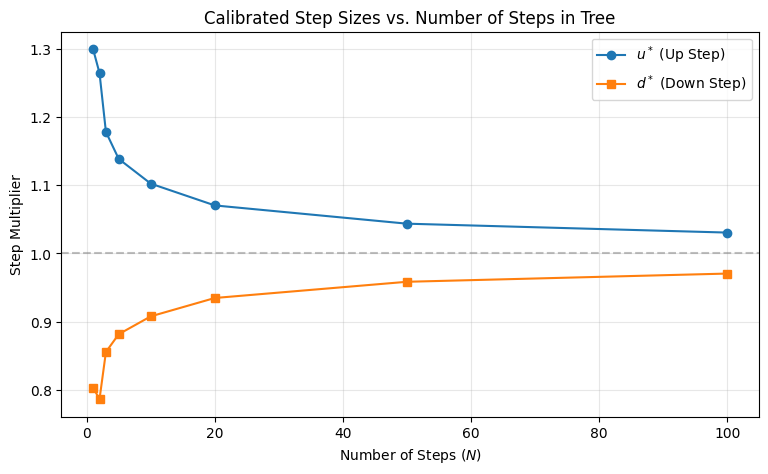

In [16]:
steps_list = [1, 2, 3, 5, 10, 20, 50, 100]
u_steps = []
d_steps = []

for n in steps_list:
    dt = T / n
    df_step = np.exp(-RATE * dt)  # Scale discount factor per step!
    
    u_calib = calibrate_tree(base_mkt_price, SPOT, STRIKE, df_step, n)
    d_calib = calcBalancedDownStep(u_calib, df_step)
    
    u_steps.append(u_calib)
    d_steps.append(d_calib)

plt.figure(figsize=(9, 5))
plt.plot(steps_list, u_steps, marker='o', label='$u^*$ (Up Step)')
plt.plot(steps_list, d_steps, marker='s', label='$d^*$ (Down Step)')
plt.title("Calibrated Step Sizes vs. Number of Steps in Tree")
plt.xlabel("Number of Steps ($N$)")
plt.ylabel("Step Multiplier")
plt.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Demo B: Calibrating a 1-Step Tree for Different Strikes (Moneyness)
**What is happening:** We change the Strike price $K$ while holding spot price at 100.
**Why:** In-The-Money (ITM), At-The-Money (ATM), and Out-Of-The-Money (OTM) options behave differently. For OTM options, the stock has to move significantly higher just to have a non-zero payoff, which forces the calibrator to find slightly different dynamics for an extreme 1-step simplification.

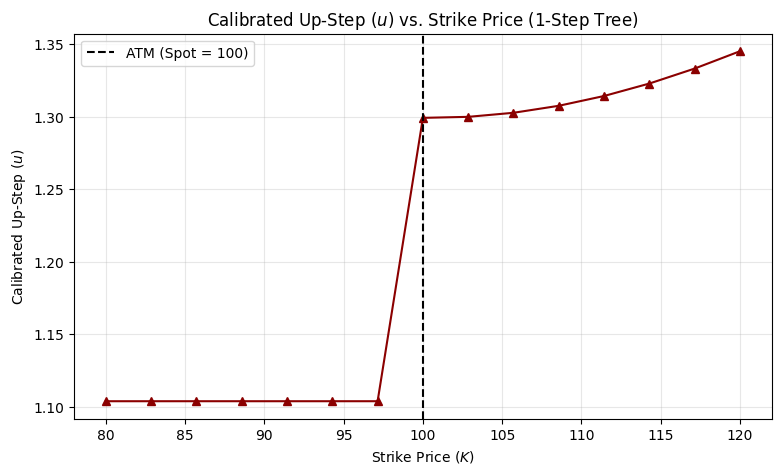

In [17]:
strikes = np.linspace(80, 120, 15)
u_strikes = []
n_steps = 1
df_1yr = np.exp(-RATE * T)

for K in strikes:
    target_price = black_scholes_call(SPOT, K, T, RATE, VOL)
    u_calib = calibrate_tree(target_price, SPOT, K, df_1yr, n_steps)
    u_strikes.append(u_calib)

plt.figure(figsize=(9, 5))
plt.plot(strikes, u_strikes, marker='^', color='darkred')
plt.title("Calibrated Up-Step ($u$) vs. Strike Price (1-Step Tree)")
plt.xlabel("Strike Price ($K$)")
plt.ylabel("Calibrated Up-Step ($u$)")
plt.axvline(SPOT, color='black', linestyle='--', label='ATM (Spot = 100)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Demo C: Calibrating a 1-Step Tree for Different Expiries
**What is happening:** We test options that expire between 3 months (0.25 years) and 3 years.
**Why:** Options with longer expiries have more time for the underlying asset to wander away from the spot price (higher total variance). Thus, a 1-step tree attempting to capture a 3-year movement requires a massively larger step size than a tree attempting to capture a 3-month movement.

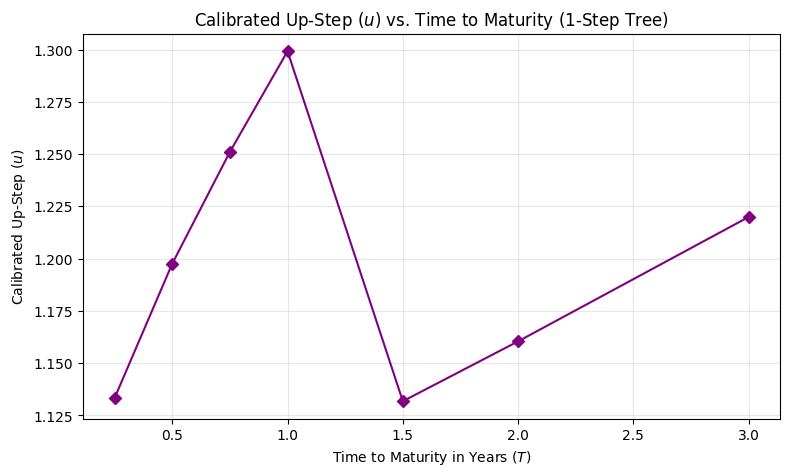

In [18]:
expiries = np.array([0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0])
u_expiries = []

for t_exp in expiries:
    target_price = black_scholes_call(SPOT, STRIKE, t_exp, RATE, VOL)
    df_t = np.exp(-RATE * t_exp)  # Scaled to the specific expiry
    
    u_calib = calibrate_tree(target_price, SPOT, STRIKE, df_t, n_steps)
    u_expiries.append(u_calib)

plt.figure(figsize=(9, 5))
plt.plot(expiries, u_expiries, marker='D', color='purple')
plt.title("Calibrated Up-Step ($u$) vs. Time to Maturity (1-Step Tree)")
plt.xlabel("Time to Maturity in Years ($T$)")
plt.ylabel("Calibrated Up-Step ($u$)")
plt.grid(True, alpha=0.3)
plt.show()

### Demo D: Calibrating against varying Volatility ($\sigma$)
**What is happening:** We test the calibrator across market volatilities ranging from 10% to 60%.
**Why:** This proves the opening premise of the assignment: **Step size directly mimics Volatility.** As the target market volatility increases, the up-step $u$ must increase in a near-linear fashion to produce matching option prices.

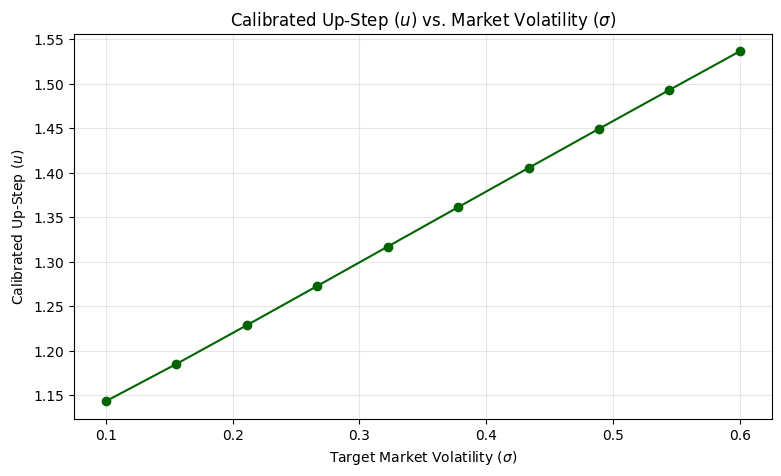

In [19]:
volatilities = np.linspace(0.10, 0.60, 10)
u_vols = []
df_1yr = np.exp(-RATE * T)

for v in volatilities:
    target_price = black_scholes_call(SPOT, STRIKE, T, RATE, v)
    u_calib = calibrate_tree(target_price, SPOT, STRIKE, df_1yr, n_steps)
    u_vols.append(u_calib)

plt.figure(figsize=(9, 5))
plt.plot(volatilities, u_vols, marker='o', color='darkgreen')
plt.title("Calibrated Up-Step ($u$) vs. Market Volatility ($\sigma$)")
plt.xlabel("Target Market Volatility ($\sigma$)")
plt.ylabel("Calibrated Up-Step ($u$)")
plt.grid(True, alpha=0.3)
plt.show()